# TP2 — Moindres carrés, régularisation, méthodes d'ensemble (corrigé)
**CNFSDP — Introduction au Machine Learning** · L3 S5 · 2026-2027 · Rois Céti DIMBAMBA · chapitre 2 · 30 min en salle

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rdimbamba/ml-cnfsdp/blob/main/notebooks/corriges/TP2_corrige.ipynb)

Partie A : moindres carrés à la main. Partie B : Ridge et Lasso sur les données `diabetes`. Partie C : boosting à la main, forêts et gradient boosting.
Les données `diabetes` sont fournies avec scikit-learn : aucun téléchargement n'est nécessaire.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, RidgeCV, LassoCV, lasso_path
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error
VERT, OR, GRIS = "#126B2A", "#B8860B", "#8A8A8A"   # couleurs du cours

## Partie A — Moindres carrés à la main
### Question 1 — Trois façons de calculer la même droite
On simule $n=100$ points de $Y=2+3X+\varepsilon$, avec $X\sim\mathcal U[0,10]$ et $\varepsilon\sim\mathcal N(0,2^2)$.
1. Calculer $\hat b=s_{xy}/s_x^2$ et $\hat a=\bar y-\hat b\,\bar x$.
2. Construire la matrice $X$ (colonne de 1, puis $x$) et résoudre les équations normales $X^\top X\theta=X^\top y$ avec `np.linalg.solve`.
3. Comparer avec `LinearRegression`, puis calculer $R^2=1-\sum e_i^2/\sum(y_i-\bar y)^2$ et le comparer à `score`.

In [2]:
rng = np.random.default_rng(1)
n = 100
x = rng.uniform(0, 10, n)
y = 2 + 3 * x + 2 * rng.standard_normal(n)

In [3]:
# 1. formules
sxy = np.mean((x - x.mean()) * (y - y.mean()))
sx2 = np.mean((x - x.mean()) ** 2)
b = sxy / sx2
a = y.mean() - b * x.mean()
print("formules           :", round(a, 4), round(b, 4))

# 2. équations normales
X = np.column_stack([np.ones(n), x])
theta = np.linalg.solve(X.T @ X, X.T @ y)
print("équations normales :", theta.round(4))

# 3. scikit-learn et R²
f = LinearRegression().fit(x.reshape(-1, 1), y)
print("scikit-learn       :", round(f.intercept_, 4), f.coef_.round(4))
e = y - (a + b * x)
R2 = 1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2)
print("R² :", round(R2, 4), "| score :", round(f.score(x.reshape(-1, 1), y), 4))
print("somme des résidus :", round(e.sum(), 10))

formules           : 1.8612 3.0038
équations normales : [1.8612 3.0038]
scikit-learn       : 1.8612 [3.0038]
R² : 0.9501 | score : 0.9501
somme des résidus : 0.0


**À commenter :** les estimations sont-elles proches des vraies valeurs $a=2$, $b=3$ ? Que vaut la somme des résidus, et pourquoi ?

## Partie B — Ridge et Lasso sur les données `diabetes`
442 patients, 10 variables (âge, sexe, IMC `bmi`, tension `bp`, six mesures sanguines `s1` à `s6`) ; la cible est la progression de la maladie un an plus tard.
On standardise les variables avant de pénaliser. Rappel des conventions : `Lasso(alpha)` correspond à $\lambda=2\,\alpha$ dans le cours, `Ridge(alpha)` à $\lambda=\alpha/n$.

In [4]:
D = load_diabetes(as_frame=True)
noms = list(D.data.columns)
Xd, yd = D.data, D.target
Xs = StandardScaler().fit_transform(Xd)        # variables standardisées (partie B, question 2)
Xd.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


### Question 2 — Le chemin du Lasso
Pour $\lambda\in\{60, 40, 20, 5, 1\}$, ajuster `Lasso(alpha=λ/2)` sur les variables standardisées et afficher les variables dont le coefficient n'est pas nul. Tracer ensuite le chemin complet avec `lasso_path`.

lambda = 60 : ['bmi', 's5']
lambda = 40 : ['bmi', 'bp', 's5']
lambda = 20 : ['bmi', 'bp', 's3', 's5']
lambda =  5 : ['sex', 'bmi', 'bp', 's1', 's3', 's5', 's6']
lambda =  1 : ['sex', 'bmi', 'bp', 's1', 's3', 's4', 's5', 's6']


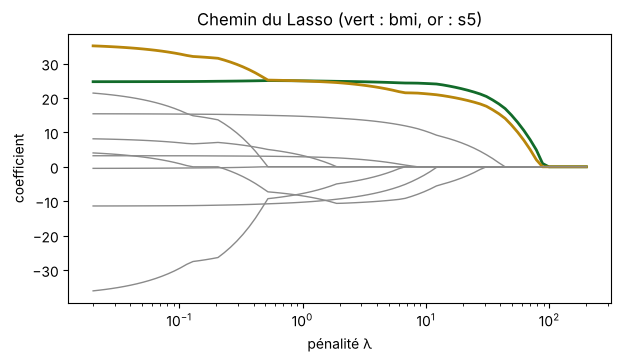

In [5]:
for lam in [60, 40, 20, 5, 1]:
    coef = Lasso(alpha=lam / 2).fit(Xs, yd).coef_
    print(f"lambda = {lam:>2} :", [nm for nm, v in zip(noms, coef) if v != 0])

alphas, coefs, _ = lasso_path(Xs, yd, alphas=np.logspace(-2, 2, 80))
plt.figure(figsize=(7, 3.5))
for j, nm in enumerate(noms):
    couleur = VERT if nm == "bmi" else OR if nm == "s5" else GRIS
    plt.plot(2 * alphas, coefs[j], color=couleur, lw=2 if couleur != GRIS else 1)
plt.xscale("log"); plt.xlabel("pénalité λ"); plt.ylabel("coefficient")
plt.title("Chemin du Lasso (vert : bmi, or : s5)"); plt.show()

**À commenter :** dans quel ordre les variables entrent-elles dans le modèle quand $\lambda$ diminue ? Quelles sont les deux plus importantes ?

### Question 3 — Choisir $\lambda$ par validation croisée
Séparer les données (70 % apprentissage, 30 % test, `random_state=0`). Dans un pipeline `StandardScaler` puis modèle, comparer sur le test la RMSE des MCO, de `RidgeCV` (grille `np.logspace(-3, 3, 50)`) et de `LassoCV(cv=5)`. Afficher le $\lambda$ retenu par chacun et les variables écartées par le Lasso.

In [6]:
Xa, Xt, ya, yt = train_test_split(Xd, yd, test_size=0.3, random_state=0)
na = len(ya)
modeles = {"MCO": LinearRegression(),
           "Ridge": RidgeCV(alphas=np.logspace(-3, 3, 50)),
           "Lasso": LassoCV(cv=5, random_state=0)}
ajustes = {}
for nom, m in modeles.items():
    ajustes[nom] = make_pipeline(StandardScaler(), m).fit(Xa, ya)
    print(f"{nom:5s} : RMSE test = {root_mean_squared_error(yt, ajustes[nom].predict(Xt)):.1f}")

print("lambda Ridge :", round(ajustes["Ridge"][-1].alpha_ / na, 4))
print("lambda Lasso :", round(2 * ajustes["Lasso"][-1].alpha_, 4))
coef = ajustes["Lasso"][-1].coef_
print("variables écartées par le Lasso :", [nm for nm, v in zip(noms, coef) if v == 0])
print("écart type de y sur le test :", round(yt.std(), 1))

MCO   : RMSE test = 55.7
Ridge : RMSE test = 55.4
Lasso : RMSE test = 55.8
lambda Ridge : 0.0828
lambda Lasso : 2.599
variables écartées par le Lasso : ['s2', 's4', 's6']
écart type de y sur le test : 71.7


**À commenter :** la régularisation améliore-t-elle nettement la prédiction ici ? Que gagne-t-on avec le Lasso ? Comparer les RMSE à l'écart type de $y$ (erreur du prédicteur constant).

## Partie C — Méthodes d'ensemble
### Question 4 — Deux étapes de boosting à la main
Sur le fil rouge du cours ($x$ = années d'études, $y$ = nombre d'enfants), partir de $F_0=\bar y$ puis, deux fois : calculer les résidus, ajuster un arbre à une coupure (`DecisionTreeRegressor(max_depth=1)`) sur les résidus, et mettre à jour $F\leftarrow F+0{,}5\,h$.
Comparer avec `GradientBoostingRegressor(n_estimators=2, learning_rate=0.5, max_depth=1)`. Le cours annonce $F_1=(4{,}67;4{,}67;4{,}67;3;3)$ et $F_2=(4{,}92;4{,}92;4{,}92;3{,}25;2)$.

In [7]:
x5 = np.array([[0], [3], [6], [9], [12]]); y5 = np.array([6, 5, 5, 3, 1])
F, nu = np.full(5, y5.mean()), 0.5
for m in range(1, 3):
    r = y5 - F                                          # résidus
    h = DecisionTreeRegressor(max_depth=1).fit(x5, r)   # petit arbre sur les résidus
    F = F + nu * h.predict(x5)
    print(f"F{m} =", F.round(3), "| coupure en x <=", h.tree_.threshold[0])

g = GradientBoostingRegressor(n_estimators=2, learning_rate=0.5, max_depth=1).fit(x5, y5)
print("scikit-learn :", g.predict(x5).round(3))

F1 = [4.667 4.667 4.667 3.    3.   ] | coupure en x <= 7.5
F2 = [4.917 4.917 4.917 3.25  2.   ] | coupure en x <= 10.5
scikit-learn : [4.917 4.917 4.917 3.25  2.   ]


### Question 5 — Linéaire, forêt ou boosting ?
Comparer la RMSE test de `LinearRegression`, `RandomForestRegressor(n_estimators=200, min_samples_leaf=5)` et `GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=2)` :
- sur $Y=\sin(2\pi X)+\varepsilon$, $\sigma=0{,}3$ (300 points d'apprentissage, 5 000 de test) ;
- sur les données `diabetes` (même découpage qu'à la question 3).

In [8]:
def simuler(n, rng):
    X = rng.uniform(0, 1, (n, 1))
    return X, np.sin(2 * np.pi * X[:, 0]) + 0.3 * rng.standard_normal(n)

rng = np.random.default_rng(0)
Xs1, ys1 = simuler(300, rng); Xs1t, ys1t = simuler(5_000, rng)

def candidats():
    return {"linéaire": LinearRegression(),
            "forêt": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=0),
            "boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.05,
                                                  max_depth=2, random_state=0)}

for titre, (A, ya_, T, yt_) in {"sinus": (Xs1, ys1, Xs1t, ys1t),
                                "diabetes": (Xa, ya, Xt, yt)}.items():
    res = {nom: root_mean_squared_error(yt_, f.fit(A, ya_).predict(T)) for nom, f in candidats().items()}
    print(titre, {k: round(v, 3) for k, v in res.items()})

sinus {'linéaire': 0.541, 'forêt': 0.316, 'boosting': 0.317}


diabetes {'linéaire': 55.652, 'forêt': 58.722, 'boosting': 58.149}


**Conclusion attendue.** Sur le sinus, forêt et boosting approchent l'écart type du bruit ($0{,}3$) alors que la droite en est loin : la relation n'est pas linéaire. Sur `diabetes`, la régression linéaire fait au moins aussi bien : avec peu de données et une relation presque linéaire, un modèle simple suffit. Aucun modèle ne gagne toujours ; on compare sur des données test.